# Phân Tích Thực Nghiệm & Dữ Liệu Huấn Luyện (`analysis.ipynb`)

**Dự án:** Multi-Level Chess AI Engine ($8 \times 8$ FIDE)  
**Phụ trách:** TV3 (UI, Arena, QA & Analytics Lead) phối hợp TV1 & TV2  

Notebook này tổng hợp toàn bộ phần kiểm tra dữ liệu và phân tích thực nghiệm:
1. **Phân tích Dữ liệu thô (`data/raw/`)**: Thống kê nhanh phân bố ELO, kết quả ván đấu và tỷ lệ vượt bộ lọc Header từ Lichess Elite Database.
2. **Nghiệm thu Dữ liệu sau ETL (`data/processed/`)**: Thống kê Train/Val/Test split, số mẫu trùng Zobrist đã loại, và kiểm tra Tensor `(18, 8, 8)` từ `ChessMemmapDataset`.
3. **Tổng hợp Kết quả Ablation 1, Ablation 2 & Giải đấu Round-Robin** (Wilson Score 95% & Paired-Opening Bootstrap 95%).

In [1]:
import json
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from chess_ai.etl.pgn_etl import inspect_raw_pgn, resolve_input_pgn_path
from chess_ai.etl.memmap_dataset import ChessMemmapDataset

print(f"Project root: {PROJECT_ROOT}")

Project root: d:\Projects\TTNTNC_local\101_chess_agent\101_TTNTNC


## 1. Phân Tích Dữ Liệu Thô Lichess Elite (`data/raw/`)
Quét nhanh 20.000 ván đầu tiên ở mức Header bằng `inspect_raw_pgn()` để kiểm tra trình độ ELO, tỷ lệ thắng/hòa/thua và các lý do bị lọc.

In [2]:
raw_pgn_path = resolve_input_pgn_path(str(PROJECT_ROOT / "data/raw/lichess_elite_2025-11.pgn"))
raw_stats = inspect_raw_pgn(str(raw_pgn_path), max_games=20000)

pd.DataFrame([
    {"Chỉ số": "Tệp nguồn", "Giá trị": Path(raw_stats["file_path"]).name},
    {"Chỉ số": "Dung lượng (MB)", "Giá trị": raw_stats["file_size_mb"]},
    {"Chỉ số": "Số ván đã quét mẫu", "Giá trị": raw_stats["games_inspected"]},
    {"Chỉ số": "Đạt bộ lọc Header", "Giá trị": f"{raw_stats['header_passed']} ({raw_stats['header_pass_rate']*100:.1f}%)"},
    {"Chỉ số": "ELO Trắng TB / Đen TB", "Giá trị": f"{raw_stats['white_elo_mean']} / {raw_stats['black_elo_mean']}"},
    {"Chỉ số": "Khoảng ELO Trắng", "Giá trị": f"{raw_stats['white_elo_min']} – {raw_stats['white_elo_max']}"},
    {"Chỉ số": "Thời gian ước lượng trung vị (giây)", "Giá trị": raw_stats["est_time_median_sec"]},
])

,Chỉ số,Giá trị
0,Tệp nguồn,lichess_elite_2025-11.pgn
1,Dung lượng (MB),255.16
2,Số ván đã quét mẫu,20000
3,Đạt bộ lọc Header,19977 (99.9%)
4,ELO Trắng TB / Đen TB,2583.5 / 2583.6
5,Khoảng ELO Trắng,2300 – 3304
6,Thời gian ước lượng trung vị (giây),180.0


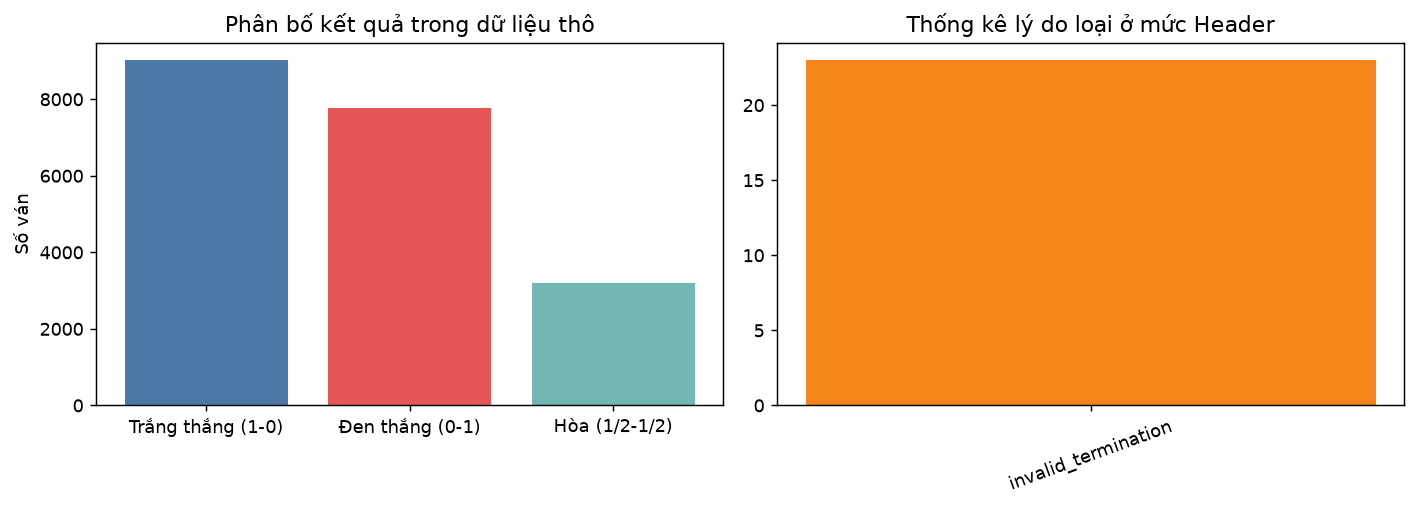

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=130)

res_dist = raw_stats["results_distribution"]
axes[0].bar(["Trắng thắng (1-0)", "Đen thắng (0-1)", "Hòa (1/2-1/2)"],
            [res_dist["1-0"], res_dist["0-1"], res_dist["1/2-1/2"]],
            color=["#4C78A8", "#E45756", "#72B7B2"])
axes[0].set_title("Phân bố kết quả trong dữ liệu thô")
axes[0].set_ylabel("Số ván")

rej = raw_stats["rejected_reasons"] or {"Đạt chuẩn": raw_stats["header_passed"]}
axes[1].bar(list(rej.keys()), list(rej.values()), color="#F58518")
axes[1].set_title("Thống kê lý do loại ở mức Header")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## 2. Nghiệm Thu Dữ Liệu Sau ETL (`data/processed/`)
Đọc `dataset_metadata.json` và kiểm tra trực tiếp `ChessMemmapDataset` (Tensor `(18, 8, 8)`, hành động `[0, 4095]` và giá trị `[-1, 1]`).

In [4]:
processed_dir = PROJECT_ROOT / "data/processed"
meta_path = processed_dir / "dataset_metadata.json"

if meta_path.exists():
    meta = json.loads(meta_path.read_text(encoding="utf-8"))
    print(f"Thời gian chạy ETL: {meta['elapsed_sec']}s | Tổng ván quét: {meta['games_scanned']:,} | Hợp lệ: {meta['valid_games']:,}")
    print(f"Tổng mẫu trích xuất: {meta['total_samples']:,} | Đã loại trùng Zobrist: {meta['zobrist_duplicates_skipped']:,}")
    split_df = pd.DataFrame([
        {"Tập dữ liệu": k, "Số ván": v["games"], "Số mẫu": v["samples"]}
        for k, v in meta["splits"].items()
    ])
    display(split_df)

    train_ds = ChessMemmapDataset(str(processed_dir), split="train")
    if len(train_ds) > 0:
        s0, a0, v0 = train_ds[0]
        print(f"Sample[0] -> state shape={tuple(s0.shape)}, dtype={s0.dtype}, action_idx={int(a0)}, value={float(v0)}")
else:
    print("Chưa có dataset_metadata.json. Hãy chạy lệnh: chess-etl --output_dir data/processed")

Thời gian chạy ETL: 118.85s | Tổng ván quét: 48,148 | Hợp lệ: 46,748
Tổng mẫu trích xuất: 1,000,000 | Đã loại trùng Zobrist: 62,690


,Tập dữ liệu,Số ván,Số mẫu
0,train,37408,800213
1,val,4659,99432
2,test,4681,100355


Sample[0] -> state shape=(18, 8, 8), dtype=torch.float32, action_idx=405, value=-1.0


## 3. Tổng Hợp Kết Quả Ablation 1 & Ablation 2
Nạp trực tiếp từ `results/ablation1/ablation1_results.json` và `results/ablation2/ablation2_results.json`.

In [5]:
ab1_path = PROJECT_ROOT / "results/ablation1/ablation1_results.json"
if ab1_path.exists():
    ab1 = json.loads(ab1_path.read_text(encoding="utf-8"))
    display(pd.DataFrame(ab1["part_1a_progressive_configs"])[["name", "tactical_accuracy", "avg_nodes", "node_reduction_vs_minimax_pct", "avg_latency_ms"]])

ab2_path = PROJECT_ROOT / "results/ablation2/ablation2_results.json"
if ab2_path.exists():
    ab2 = json.loads(ab2_path.read_text(encoding="utf-8"))
    display(pd.DataFrame(ab2["part_2a_uct_level4"])[["simulations", "score", "wins", "draws", "losses", "agent_a_avg_latency_ms"]])

,name,tactical_accuracy,avg_nodes,node_reduction_vs_minimax_pct,avg_latency_ms
0,Config_A,0.54,51494.88,0.00,3013.756
1,Config_B,0.54,7245.94,85.93,372.921
2,Config_C1,0.54,2016.00,96.09,107.672
3,Config_C2,0.54,1961.60,96.19,106.876
4,Config_D,0.74,4704.32,90.86,181.306


,simulations,score,wins,draws,losses,agent_a_avg_latency_ms
0,50,0.00,0,0,50,162.426
1,100,0.02,1,0,49,329.579
2,200,0.00,0,0,50,659.813
3,400,0.01,0,1,49,1416.268
4,800,0.01,0,1,49,2697.994
5,1000,0.01,0,1,49,3275.777
